In [1]:
import json, sys, time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from scipy.stats import spearmanr
from tqdm.auto import tqdm

from ml.config import data_root
from ml.datasets.targets import DISPLAY_NAMES, NIH_FINDINGS, TB, label_column
from ml.explain.occlusion import (OcclusionConfig, OcclusionResult, box_mask, deletion_score, energy_in_box,
                                  occlusion_map, overlay, platt_calibrator, pointing_hit, smooth_random_map)
from ml.training.data import XrayDataset, load_processed
from ml.training.model import build_model
from ml.training.train import predict

ROOT = data_root()
FIG = REPO / "docs" / "figures" / "explain"       # aggregate numbers and charts only
LOCAL = ROOT / "processed" / "explain"             # heatmap cache and X-ray figures stay local
FIG.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG = OcclusionConfig()                            # patch 32, stride 16, blurred baseline


def load_model(run: str, n_out: int):
    m = build_model(n_out, pretrained=False, memory_efficient=False).to(DEV)
    ckpt = torch.load(REPO / "ml" / "checkpoints" / run / "best.pt", map_location=DEV, weights_only=False)
    m.load_state_dict(ckpt["model"])
    return m.eval()


nih_model, tb_model = load_model("nih_densenet121_v1", len(NIH_FINDINGS)), load_model("tb_densenet121_v2", 1)
nih_cfg = json.loads((REPO / "ml" / "configs" / "nih_v1_calibration.json").read_text())["findings"]
tb_cfg = json.loads((REPO / "ml" / "configs" / "tb_v2_calibration.json").read_text())["findings"]
nih_cal, tb_cal = platt_calibrator(nih_cfg, NIH_FINDINGS), platt_calibrator(tb_cfg, [TB])
MODELS = {"nih": (nih_model, nih_cal), "tb": (tb_model, tb_cal)}
nih = load_processed(ROOT, "nih")


def read(path: str) -> np.ndarray:
    return np.asarray(Image.open(ROOT / path))


def explain(kind: str, image_id: str, path: str, cfg: OcclusionConfig = CFG) -> OcclusionResult:
    """Occlusion heatmaps with a disk cache, so reruns are instant."""
    key = f"{kind}_p{cfg.patch}_s{cfg.stride}_{cfg.baseline}_{image_id.replace(':', '_').replace('/', '_')}"
    f = LOCAL / "cache" / f"{key}.npz"
    if f.exists():
        z = np.load(f)
        return OcclusionResult(z["heat"].astype(np.float32) if z["ok"] else None, z["scores"], str(z["status"]), 0)
    model, cal = MODELS[kind]
    res = occlusion_map(model, read(path), DEV, cal, cfg)
    f.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(f, heat=(res.heatmaps if res.heatmaps is not None else np.zeros(1)).astype(np.float16),
                        scores=res.scores, status=res.status, ok=res.heatmaps is not None)
    return res


print("device", DEV, "| NIH test images", int((nih["split"] == "test").sum()))

device cuda | NIH test images 25588


In [2]:
sample = nih[nih["split"] == "test"].iloc[0]
for kind in ("nih", "tb"):
    model, cal = MODELS[kind]
    occlusion_map(model, read(sample["processed_path"]), DEV, cal, CFG)          # warm-up
    if DEV.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    res = occlusion_map(model, read(sample["processed_path"]), DEV, cal, CFG)
    if DEV.type == "cuda":
        torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / 1e9 if DEV.type == "cuda" else float("nan")
    print(f"{kind}: {time.time() - t0:.2f} s per image | status {res.status} | batch {res.batch_size_used} | peak {peak:.2f} GB")

nih: 1.45 s per image | status ok | batch 32 | peak 0.44 GB
tb: 1.44 s per image | status ok | batch 32 | peak 0.44 GB


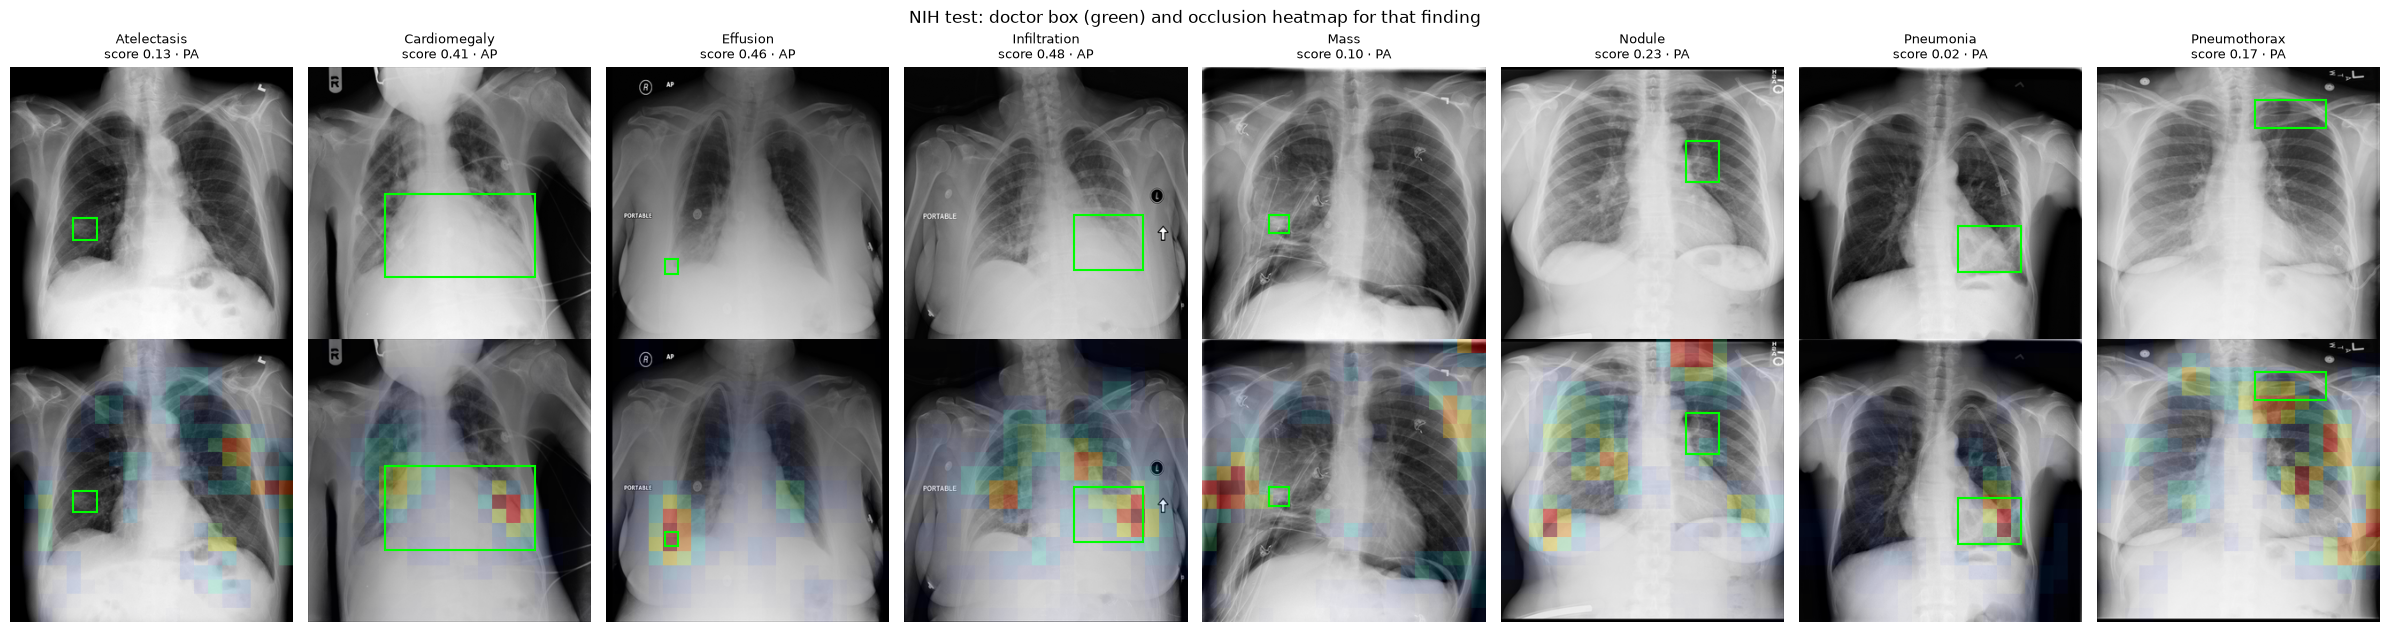

In [2]:
boxes = pd.read_csv(ROOT / "processed" / "manifests" / "nih_bboxes_320.csv")
boxes = boxes[boxes["label_present"]].merge(nih[["image_id", "processed_path", "view"]], on="image_id")
pick = boxes.groupby("finding").head(1).reset_index(drop=True)
fig, axes = plt.subplots(2, len(pick), figsize=(3 * len(pick), 6.4), squeeze=False)
for col, r in enumerate(pick.itertuples()):
    img, res = read(r.processed_path), explain("nih", r.image_id, r.processed_path)
    k = NIH_FINDINGS.index(r.finding)
    for row_, show in enumerate((img, overlay(img, res.heatmaps[k]))):
        ax = axes[row_, col]
        ax.imshow(show, cmap="gray" if row_ == 0 else None)
        ax.add_patch(plt.Rectangle((r.x_320, r.y_320), r.w_320, r.h_320, fill=False, color="lime", linewidth=1.5))
        ax.axis("off")
    axes[0, col].set_title(f"{DISPLAY_NAMES[r.finding]}\nscore {res.scores[k]:.2f} · {r.view}", fontsize=9)
fig.suptitle("NIH test: doctor box (green) and occlusion heatmap for that finding")
plt.tight_layout(); fig.savefig(LOCAL / "gallery_nih.png", dpi=120); plt.show()

NIH box images:   0%|          | 0/880 [00:00<?, ?it/s]

,boxes,pointing_hit,chance,energy_in_box,lift_vs_chance
finding,,,,,
Atelectasis,180.0,0.228,0.033,0.082,6.887
Cardiomegaly,146.0,0.856,0.179,0.403,4.778
Effusion,153.0,0.412,0.071,0.197,5.840
Infiltration,123.0,0.512,0.099,0.201,5.166
Mass,85.0,0.376,0.043,0.124,8.670
Nodule,79.0,0.266,0.006,0.037,46.804
Pneumonia,120.0,0.492,0.096,0.174,5.106
Pneumothorax,98.0,0.184,0.053,0.102,3.435
All findings,984.0,0.429,0.077,0.176,5.550


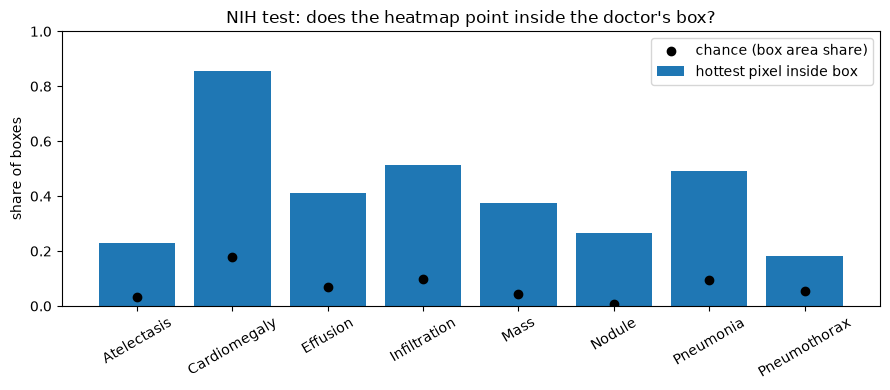

In [4]:
rows = []
for image_id, grp in tqdm(boxes.groupby("image_id"), desc="NIH box images"):
    res = explain("nih", image_id, grp["processed_path"].iloc[0])
    if res.heatmaps is None:
        continue
    for r in grp.itertuples():
        heat, box = res.heatmaps[NIH_FINDINGS.index(r.finding)], (r.x_320, r.y_320, r.w_320, r.h_320)
        rows.append({"finding": DISPLAY_NAMES[r.finding], "image_id": image_id, "view": r.view,
                     "pointing_hit": pointing_hit(heat, box), "energy_in_box": energy_in_box(heat, box),
                     "box_area_share": box_mask(heat.shape, box).mean()})
ov = pd.DataFrame(rows)
by = ov.groupby("finding").agg(boxes=("pointing_hit", "size"), pointing_hit=("pointing_hit", "mean"),
                               chance=("box_area_share", "mean"), energy_in_box=("energy_in_box", "mean"))
by.loc["All findings"] = [len(ov), ov["pointing_hit"].mean(), ov["box_area_share"].mean(), ov["energy_in_box"].mean()]
by["lift_vs_chance"] = by["pointing_hit"] / by["chance"]
display(by.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
plot = by.drop("All findings")
ax.bar(plot.index, plot["pointing_hit"], label="hottest pixel inside box")
ax.scatter(plot.index, plot["chance"], color="black", zorder=3, label="chance (box area share)")
ax.set_ylim(0, 1); ax.set_ylabel("share of boxes"); ax.tick_params(axis="x", rotation=30); ax.legend()
ax.set_title("NIH test: does the heatmap point inside the doctor's box?")
plt.tight_layout(); fig.savefig(FIG / "nih_v1_box_pointing.png", dpi=150); plt.show()

In [5]:
rng = np.random.default_rng(42)
DEL_N, FRAC = 120, 0.10
del_rows = []
one_box = boxes.drop_duplicates("image_id")
for r in tqdm(one_box.sample(min(DEL_N, len(one_box)), random_state=1).itertuples(), desc="deletion"):
    img, res = read(r.processed_path), explain("nih", r.image_id, r.processed_path)
    k = NIH_FINDINGS.index(r.finding)
    top = deletion_score(nih_model, img, res.heatmaps[k], k, DEV, FRAC, nih_cal, CFG)
    rand = np.mean([deletion_score(nih_model, img, smooth_random_map(img.shape, rng), k, DEV, FRAC, nih_cal, CFG)
                    for _ in range(3)])
    del_rows.append({"finding": DISPLAY_NAMES[r.finding], "original": res.scores[k], "after_top": top, "after_random": rand})
dl = pd.DataFrame(del_rows)
dl["drop_top"], dl["drop_random"] = dl["original"] - dl["after_top"], dl["original"] - dl["after_random"]
print(f"hide hottest {FRAC:.0%}: mean drop {dl['drop_top'].mean():.3f} | "
      f"hide random {FRAC:.0%}: {dl['drop_random'].mean():.3f} | "
      f"heatmap beats random in {(dl['drop_top'] > dl['drop_random']).mean():.0%} of {len(dl)} images")
display(dl.groupby("finding")[["original", "drop_top", "drop_random"]].mean().round(3))

deletion: 0it [00:00, ?it/s]

hide hottest 10%: mean drop 0.189 | hide random 10%: 0.049 | heatmap beats random in 99% of 120 images


,original,drop_top,drop_random
finding,,,
Atelectasis,0.220,0.136,0.033
Cardiomegaly,0.200,0.193,0.055
Effusion,0.448,0.307,0.096
Infiltration,0.320,0.206,0.057
Mass,0.347,0.291,0.054
Nodule,0.194,0.140,0.015
Pneumonia,0.061,0.053,0.019
Pneumothorax,0.272,0.217,0.053


In [6]:
STAB_N = 20
variants = {"patch 24": OcclusionConfig(patch=24, stride=12), "patch 48": OcclusionConfig(patch=48, stride=24),
            "mean fill": OcclusionConfig(baseline="mean")}
def hot_region(m: np.ndarray) -> tuple[int, int]:
    """Which cell of a 5 x 5 grid holds the hottest pixel."""
    y, x = np.unravel_index(m.argmax(), m.shape)
    return y * 5 // m.shape[0], x * 5 // m.shape[1]


stab = []
for r in tqdm(one_box.sample(min(STAB_N, len(one_box)), random_state=2).itertuples(), desc="stability"):
    k = NIH_FINDINGS.index(r.finding)
    ref = explain("nih", r.image_id, r.processed_path).heatmaps[k]
    for name, cfg in variants.items():
        alt = explain("nih", r.image_id, r.processed_path, cfg).heatmaps[k]
        stab.append({"variant": name, "spearman": spearmanr(ref[::8, ::8].ravel(), alt[::8, ::8].ravel()).statistic,
                     "same_hotspot": hot_region(ref) == hot_region(alt)})
st = pd.DataFrame(stab).groupby("variant").agg(spearman_median=("spearman", "median"), same_hotspot_region=("same_hotspot", "mean"))
display(st.round(3))

stability: 0it [00:00, ?it/s]

,spearman_median,same_hotspot_region
variant,,
mean fill,0.738,0.55
patch 24,0.772,0.45
patch 48,0.756,0.50


Edema AP: 0it [00:00, ?it/s]

Edema PA: 0it [00:00, ?it/s]

Effusion AP: 0it [00:00, ?it/s]

Effusion PA: 0it [00:00, ?it/s]

Share of positive heat in the outer 12% frame (frame = 42% of the image area; lower = more central):


view,AP,PA
finding,,
Edema,0.149,0.194
Effusion,0.196,0.199


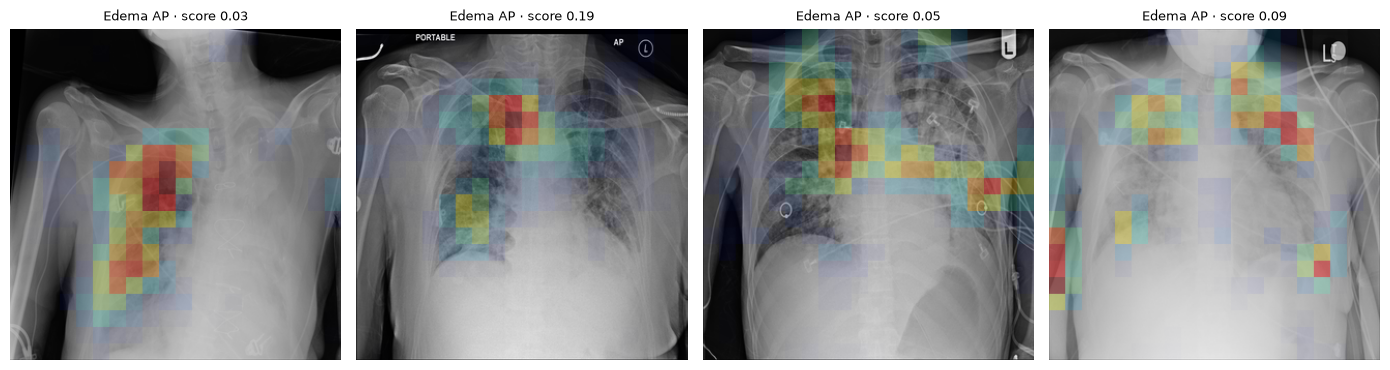

In [7]:
def border_share(heat: np.ndarray, frac: float = 0.12) -> float:
    """Share of positive heat in the outer frame, where text markers, tubes and padding sit."""
    pos, h, w = np.clip(heat, 0, None), heat.shape[0], heat.shape[1]
    inner = np.zeros_like(pos, dtype=bool)
    inner[int(h * frac):int(h * (1 - frac)), int(w * frac):int(w * (1 - frac))] = True
    return float(pos[~inner].sum() / pos.sum()) if pos.sum() > 0 else float("nan")

test = nih[nih["split"] == "test"]
det = []
for f in ("Edema", "Effusion"):
    for view in ("AP", "PA"):
        pool = test[(test[label_column(f)] == 1) & (test["view"] == view)]
        grp = pool.sample(min(25, len(pool)), random_state=3)
        for r in tqdm(grp.itertuples(), desc=f"{f} {view}", leave=False):
            res = explain("nih", r.image_id, r.processed_path)
            det.append({"finding": f, "view": view, "border_share": border_share(res.heatmaps[NIH_FINDINGS.index(f)])})
print("Share of positive heat in the outer 12% frame (frame = 42% of the image area; lower = more central):")
display(pd.DataFrame(det).groupby(["finding", "view"])["border_share"].median().unstack().round(3))

ed = test[(test[label_column("Edema")] == 1) & (test["view"] == "AP")].sample(4, random_state=4)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, r in zip(axes, ed.itertuples()):
    res = explain("nih", r.image_id, r.processed_path)
    ax.imshow(overlay(read(r.processed_path), res.heatmaps[NIH_FINDINGS.index("Edema")]))
    ax.set_title(f"Edema AP · score {res.scores[NIH_FINDINGS.index('Edema')]:.2f}", fontsize=9); ax.axis("off")
plt.tight_layout(); fig.savefig(LOCAL / "edema_ap.png", dpi=120); plt.show()

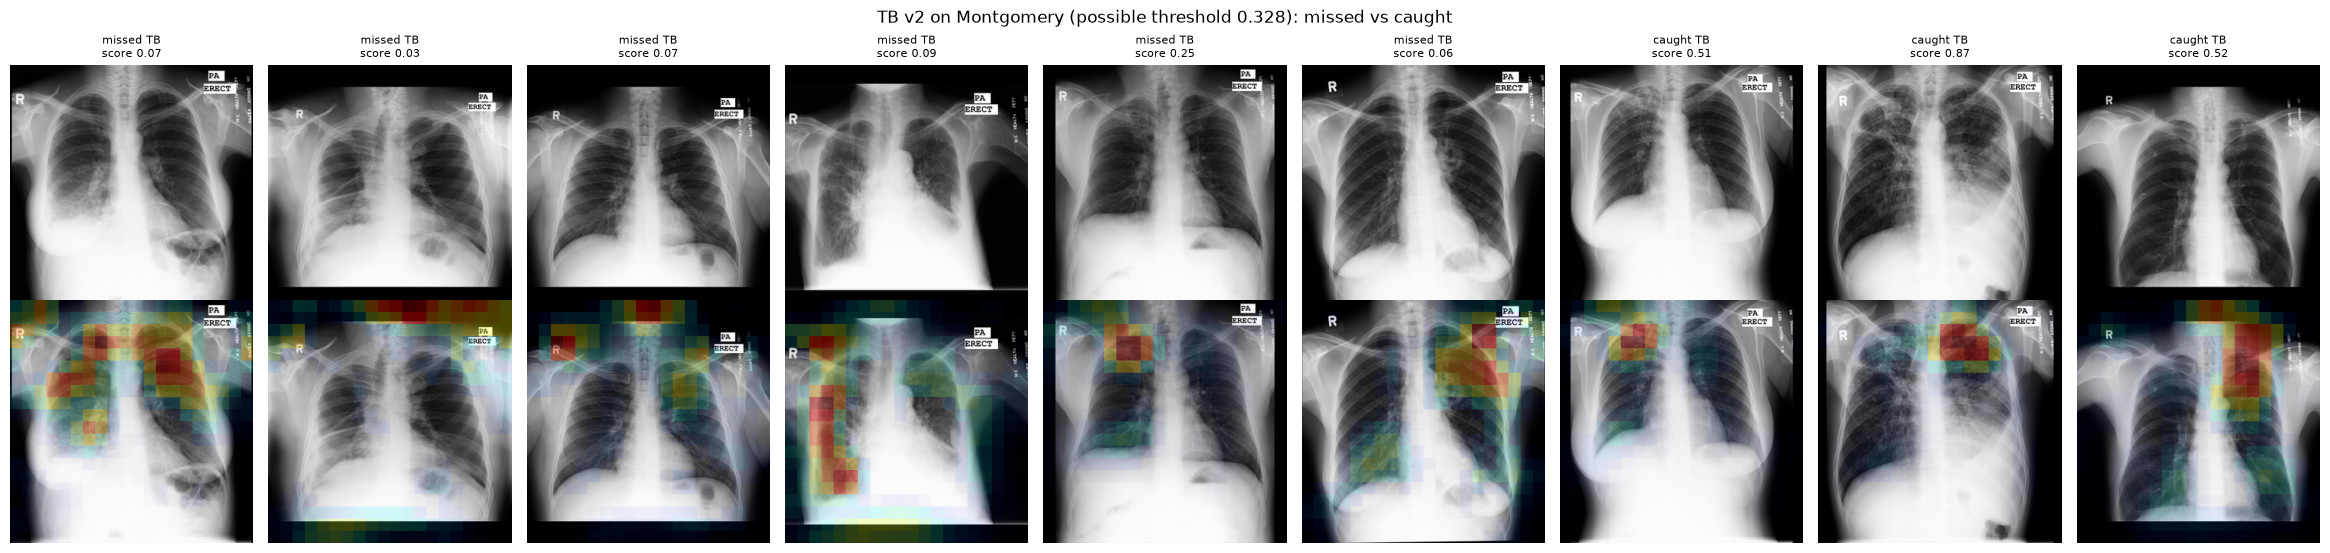

In [3]:
mg = load_processed(ROOT, "montgomery").reset_index(drop=True)
mg_dl = torch.utils.data.DataLoader(XrayDataset(mg, ROOT, [label_column(TB)]), batch_size=32)
mg["tb_score"] = tb_cal(predict(tb_model, mg_dl, DEV))[:, 0]
thr = tb_cfg[TB]["possible_threshold"]
show = pd.concat([mg[(mg[label_column(TB)] == 1) & (mg["tb_score"] < thr)].sample(6, random_state=5).assign(kind="missed TB"),
                  mg[(mg[label_column(TB)] == 1) & (mg["tb_score"] >= thr)].sample(3, random_state=5).assign(kind="caught TB")])
fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.6))
for col, r in enumerate(show.itertuples()):
    img, res = read(r.processed_path), explain("tb", r.image_id, r.processed_path)
    axes[0, col].imshow(img, cmap="gray"); axes[0, col].set_title(f"{r.kind}\nscore {r.tb_score:.2f}", fontsize=8)
    axes[1, col].imshow(overlay(img, res.heatmaps[0]))
    for ax in axes[:, col]:
        ax.axis("off")
fig.suptitle(f"TB v2 on Montgomery (possible threshold {thr:.3f}): missed vs caught")
plt.tight_layout(); fig.savefig(LOCAL / "tb_montgomery.png", dpi=120); plt.show()

In [9]:
(FIG / "occlusion_summary.json").write_text(json.dumps({
    "config": {"patch": CFG.patch, "stride": CFG.stride, "baseline": CFG.baseline, "blur_sigma": CFG.blur_sigma},
    "box_overlap": by.reset_index().to_dict("records"),
    "deletion": {"fraction": FRAC, "images": len(dl), "mean_drop_top": float(dl["drop_top"].mean()),
                 "mean_drop_random": float(dl["drop_random"].mean()),
                 "heatmap_beats_random": float((dl["drop_top"] > dl["drop_random"]).mean())},
    "stability": st.reset_index().to_dict("records"),
    "edema_border_share": pd.DataFrame(det).groupby(["finding", "view"])["border_share"].median().reset_index().to_dict("records"),
}, indent=2, default=str))
print("saved", FIG / "occlusion_summary.json")

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\docs\figures\explain\occlusion_summary.json


reason,below_possible,shown,weak_evidence,region_touches_box,region_area
finding,,,,,
Atelectasis,8,172,0,0.697674,0.045
Cardiomegaly,8,138,0,1.0,0.056
Effusion,3,149,1,0.879195,0.049
Infiltration,6,117,0,0.923077,0.070
Mass,3,82,0,0.768293,0.037
Nodule,2,77,0,0.727273,0.042
Pneumonia,7,113,0,0.840708,0.060
Pneumothorax,2,96,0,0.65625,0.058


maps shown 96% of 984 | outlined region touches the box in 82% of shown maps | median region = 5.2% of image


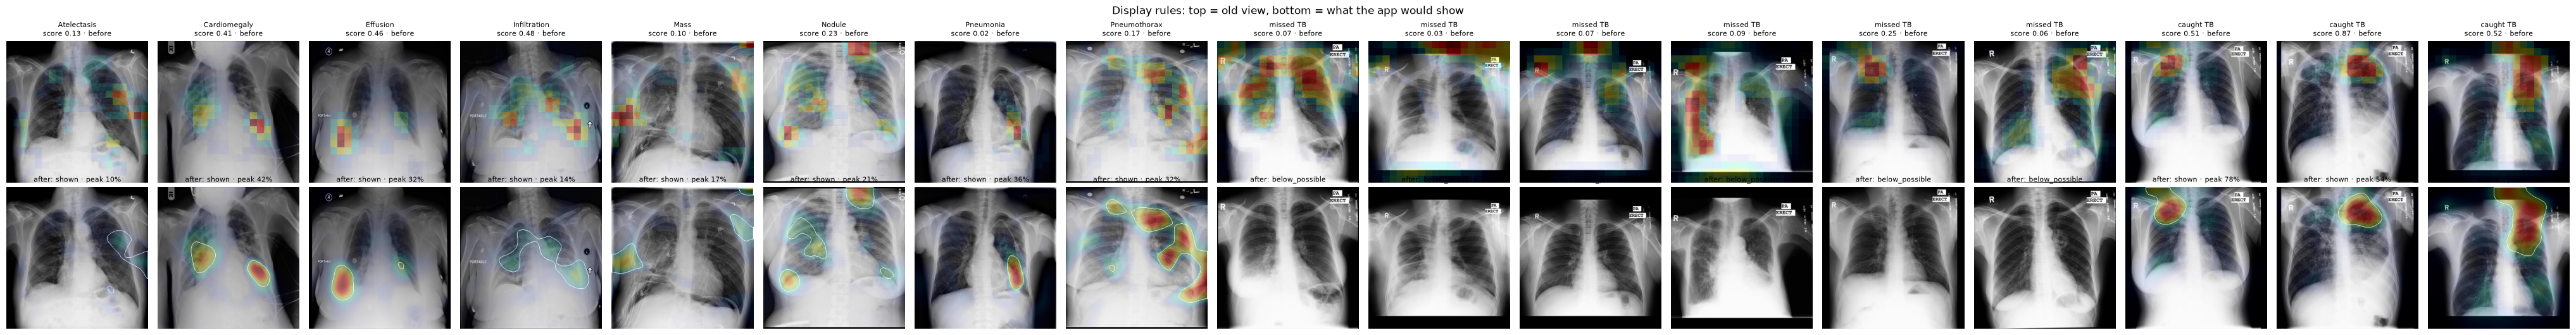

In [4]:
# ==== CELL 10: display rules (only possible/likely, score-tied colour scale, region outline) ====
from ml.explain.occlusion import DisplayConfig, display_map

DCFG = DisplayConfig()


def possible_thr(cfg: dict, name: str) -> float | None:
    return cfg[name]["possible_threshold"] if cfg[name]["status"] == "banded" else None


# 1) how many NIH box maps would be shown, and does the outlined region touch the doctor's box?
drows = []
for image_id, grp in boxes.groupby("image_id"):
    res = explain("nih", image_id, grp["processed_path"].iloc[0])
    for r in grp.itertuples():
        k = NIH_FINDINGS.index(r.finding)
        dm = display_map(None if res.heatmaps is None else res.heatmaps[k], float(res.scores[k]),
                         possible_thr(nih_cfg, r.finding), DCFG)
        hit = bool((dm.region & box_mask(dm.region.shape, (r.x_320, r.y_320, r.w_320, r.h_320))).any()) \
            if dm.region is not None else np.nan
        drows.append({"finding": DISPLAY_NAMES[r.finding], "reason": dm.reason, "region_touches_box": hit,
                      "region_area": dm.region.mean() if dm.region is not None else np.nan})
dd = pd.DataFrame(drows)
summary = pd.crosstab(dd["finding"], dd["reason"])
summary["region_touches_box"] = dd.groupby("finding")["region_touches_box"].mean()
summary["region_area"] = dd.groupby("finding")["region_area"].median()
display(summary.round(3))
print(f"maps shown {(dd['reason'] == 'shown').mean():.0%} of {len(dd)} | outlined region touches the box in "
      f"{dd['region_touches_box'].mean():.0%} of shown maps | median region = {dd['region_area'].median():.1%} of image")

# 2) before (own-max scale) vs after (display rules), on the gallery and Montgomery images from cells 3 and 8
cases = [("nih", r.image_id, r.processed_path, r.finding, DISPLAY_NAMES[r.finding]) for r in pick.itertuples()] + \
        [("tb", r.image_id, r.processed_path, TB, r.kind) for r in show.itertuples()]
fig, axes = plt.subplots(2, len(cases), figsize=(2.4 * len(cases), 5.4), squeeze=False)
for col, (kind, image_id, path, name, label) in enumerate(cases):
    img, res = read(path), explain(kind, image_id, path)
    k = NIH_FINDINGS.index(name) if kind == "nih" else 0
    score = float(res.scores[k])
    dm = display_map(res.heatmaps[k], score, possible_thr(nih_cfg if kind == "nih" else tb_cfg, name), DCFG)
    axes[0, col].imshow(overlay(img, res.heatmaps[k]))
    axes[0, col].set_title(f"{label}\nscore {score:.2f} · before", fontsize=8)
    axes[1, col].imshow(overlay(img, dm.heat, vmax=dm.vmax, region=dm.region) if dm.heat is not None else img,
                        cmap=None if dm.heat is not None else "gray")
    axes[1, col].set_title(f"after: {dm.reason}" + (f" · peak {dm.peak:.0%}" if dm.heat is not None else ""),
                           fontsize=8)
    for ax in axes[:, col]:
        ax.axis("off")
fig.suptitle("Display rules: top = old view, bottom = what the app would show")
plt.tight_layout(); fig.savefig(LOCAL / "display_rules.png", dpi=120); plt.show()